# Linear regression: Reliance daily return

Part of the ML Portfolio Model Zoo. Educational purposes only.

Predict Reliance Industries' daily return from the Nifty 50 return, the Nifty Energy return and unusual volume, using **real** prices from Yahoo Finance. This notebook walks through the data audit first, then the model. Everything reuses `train.py`, so the notebook and the site share one pipeline.

In [1]:
import tempfile
from pathlib import Path

import pandas as pd
from IPython.display import Image, display
from train import *

pd.set_option('display.width', 160)

## 1. Download

`load_raw()` reads the cached `data/raw_yahoo.csv`, or downloads it from Yahoo Finance the first time (`load_raw(refresh=True)` forces a fresh download). Tickers: `RELIANCE.NS`, `^NSEI` (Nifty 50), `^CNXENERGY` (Nifty Energy).

In [2]:
raw = load_raw()
print(raw.shape)
raw['Close'].tail()

(2930, 18)


Ticker,RELIANCE.NS,^CNXENERGY,^NSEI
Date,,,
2026-11-06,1320.000000,36867.300781,25030.349609
2026-11-09,1324.400024,37164.949219,25044.650391
2026-11-11,1335.400024,37548.050781,25255.050781
2026-11-12,1339.699951,37389.101562,25299.349609
2026-11-13,1339.699951,37399.050781,25144.300781


## 2. Check for missing data

The indices have no close on some days Reliance traded (holidays, special sessions). Forward-filling would invent zero returns, so these days are dropped.

In [3]:
close = raw['Close']
print(close.isna().sum())
close[close.isna().any(axis=1)].head(10)

Ticker
RELIANCE.NS     0
^CNXENERGY     19
^NSEI           9
dtype: int64


Ticker,RELIANCE.NS,^CNXENERGY,^NSEI
Date,,,
2015-01-01,202.959000,8630.950195,NaN
2015-04-15,211.130859,8838.049805,NaN
2016-01-01,232.091934,8594.700195,NaN
2016-08-12,236.766449,9434.500000,NaN
2018-01-01,415.907104,14138.950195,NaN
2019-01-01,512.483459,14348.000000,NaN
2019-10-27,655.690857,NaN,NaN
2020-11-14,924.061096,NaN,NaN
2021-01-01,917.230957,NaN,14018.500000


In [4]:
vol = raw[('Volume', TICKERS['stock'])]
print('zero-volume days for Reliance:', list(vol.index[vol == 0].date))
print('duplicate dates:', raw.index.duplicated().sum(), '  non-positive prices:', int((close <= 0).sum().sum()))

zero-volume days for Reliance: [datetime.date(2025, 3, 18), datetime.date(2026, 1, 15)]
duplicate dates: 0   non-positive prices: 0


## 3. Clean and look for outliers

`prepare()` aligns the dates, computes returns, and applies the rules described in the README. Large moves are not automatically errors: crash days are real, so each rule either drops, caps or only flags.

In [5]:
data, audit = prepare(raw)
for note in audit.notes:
    print('-', note)
print()
audit.counts

- 25 days dropped because an index or the stock had no close
- 1 days dropped for zero stock volume
- 21 days had volume outside 0.2-4x the average and were capped
- 21 days dropped for a market or sector move beyond +/-5%
- 17 days flagged as stock-specific outliers (|robust z| > 5) and kept



{'raw_rows': 2930,
 'first_date': '2015-01-01',
 'last_date': '2026-11-13',
 'duplicate_dates': 0,
 'non_positive_prices': 0,
 'missing_close': {'stock': 0, 'market': 9, 'sector': 19},
 'dropped_missing_close': 25,
 'dropped_zero_volume': 1,
 'dropped_warmup': 20,
 'stale_stock_prices': 1,
 'volume_capped': 21,
 'dropped_out_of_range': 21,
 'flagged_outliers': 17,
 'rows_used': 2862}

In [6]:
print('Flagged as stock-specific outliers (kept):')
audit.flagged.round(2)

Flagged as stock-specific outliers (kept):


,market_return_pct,sector_return_pct,volume_ratio,stock_return_pct,residual_z
Date,,,,,
2017-02-22,0.21,3.57,4.00,10.96,10.8
2017-02-27,-0.48,1.31,3.82,4.75,5.3
2018-10-08,0.31,4.14,2.26,5.77,5.5
2019-08-13,-1.65,1.90,4.00,9.69,11.4
2020-03-26,3.89,0.78,0.99,-1.48,-5.4
2020-04-22,2.29,3.27,3.19,10.20,7.9
2020-04-24,-1.71,0.50,2.76,3.36,5.2
2020-05-12,-0.46,-1.98,1.69,-6.19,-5.6
2020-08-04,1.87,2.34,1.47,7.05,5.2


In [7]:
print('Dropped for a market or sector move beyond +/-5%:')
audit.out_of_range.round(2)

Dropped for a market or sector move beyond +/-5%:


,market_return_pct,sector_return_pct,volume_ratio,stock_return_pct
Date,,,,
2015-08-24,-5.92,-8.31,2.90,-8.63
2018-10-04,-2.39,-6.14,2.39,-6.87
2018-10-05,-2.67,-7.97,2.13,-6.54
2019-09-20,5.32,4.04,2.67,6.39
2020-03-09,-4.90,-6.46,4.00,-12.34
2020-03-12,-8.30,-9.63,2.03,-7.85
2020-03-16,-7.61,-6.00,1.18,-8.11
2020-03-18,-5.56,-4.50,1.27,-3.92
2020-03-20,5.83,8.63,1.62,10.92


In [8]:
data.describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
market_return_pct,2862.0,0.05,0.90,-4.38,-0.43,0.06,0.59,4.74
sector_return_pct,2862.0,0.08,1.16,-4.96,-0.61,0.10,0.80,4.61
volume_ratio,2862.0,1.01,0.51,0.20,0.69,0.89,1.18,4.00
stock_return_pct,2862.0,0.09,1.57,-8.62,-0.85,0.06,0.94,11.60


## 4. Train and evaluate

Chronological split: the earlier 75% of days train, the most recent 25% test. `train_and_evaluate()` also exports to ONNX and asserts that onnxruntime reproduces scikit-learn.

In [9]:
result = train_and_evaluate()
m = result.metrics
print(f"train {m['train_period']}  ({m['n_train']} days)")
print(f"test  {m['test_period']}  ({m['n_test']} days)")
print(f"R2 {m['r2']:.3f}   RMSE {m['rmse']:.2f}   MAE {m['mae']:.2f}   (always-the-mean RMSE {m['mean_baseline_rmse']:.2f})")
print(f"market-only R2 {m['market_only_r2']:.3f}   beta {m['beta']:.2f}")
print(f"ONNX vs sklearn max abs diff: {m['onnx_max_abs_diff']:.1e}")

train 2015-02-02 to 2023-11-30  (2146 days)


test  2023-12-01 to 2026-11-12  (716 days)
R2 0.319   RMSE 1.12   MAE 0.83   (always-the-mean RMSE 1.36)
market-only R2 0.407   beta 1.02
ONNX vs sklearn max abs diff: 4.5e-07


The full model does worse out of sample than the market-only fit. The next cell shows why.

In [10]:
from itertools import combinations

train, test = data.iloc[:result.n_train], data.iloc[result.n_train:]
rows = []
for k in (1, 2, 3):
    for cols in combinations(COLUMNS, k):
        cols = list(cols)
        fit = LinearRegression().fit(train[cols], train[TARGET])
        rows.append({'features': ' + '.join(c.replace('_return_pct', '').replace('_ratio', '') for c in cols),
                     'train R2': r2_score(train[TARGET], fit.predict(train[cols])),
                     'test R2': r2_score(test[TARGET], fit.predict(test[cols]))})
pd.DataFrame(rows).round(3)

,features,train R2,test R2
0,market,0.331,0.407
1,sector,0.617,0.297
2,volume,0.021,-0.010
3,market + sector,0.618,0.307
4,market + volume,0.358,0.401
5,sector + volume,0.630,0.304
6,market + sector + volume,0.631,0.319


In [11]:
# The sector index contains Reliance itself, and its link to Reliance weakens over time.
rows = []
for start in (2016, 2018, 2020, 2022, 2024):
    d = data.loc[str(start):str(start + 1)]
    coefs = LinearRegression().fit(d[COLUMNS], d[TARGET]).coef_
    rows.append({'window': f'{start}-{start + 1}', **dict(zip(['market', 'sector', 'volume'], coefs))})
pd.DataFrame(rows).round(2)

,window,market,sector,volume
0,2016-2017,-0.39,1.43,0.35
1,2018-2019,-0.22,1.28,0.34
2,2020-2021,0.19,0.90,0.44
3,2022-2023,0.58,0.59,0.05
4,2024-2025,0.72,0.36,0.14


## 5. Charts

The same charts the site shows, written to a temporary folder.

The three closing-price series from Yahoo Finance, rebased to 100. Reliance has tracked the Nifty 50 with more swing.


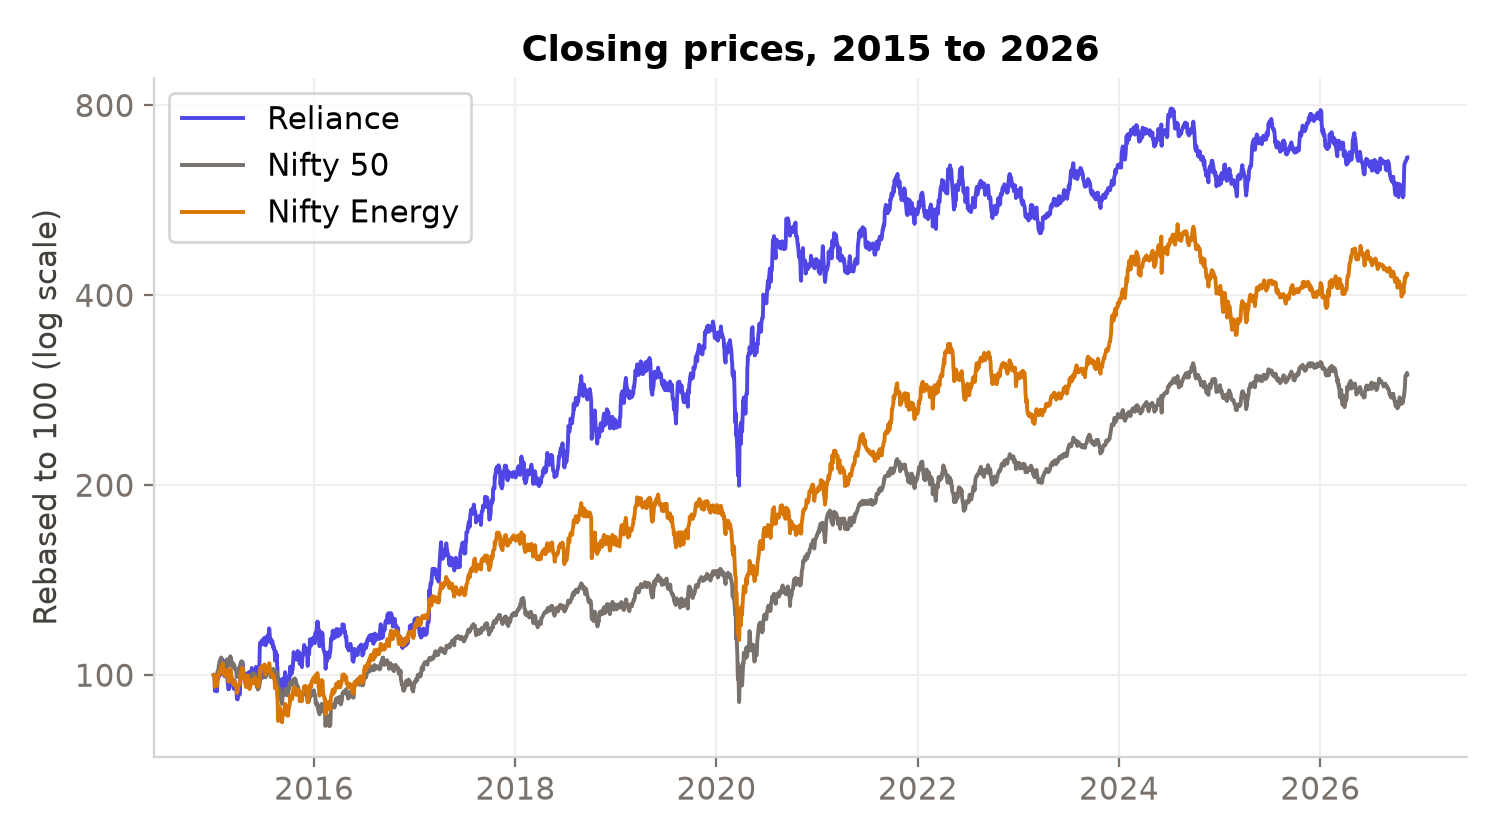

Daily Reliance return against the Nifty 50 return. Red circles are stock-specific outliers that were kept; orange crosses are crash and election-day moves outside the form's range.


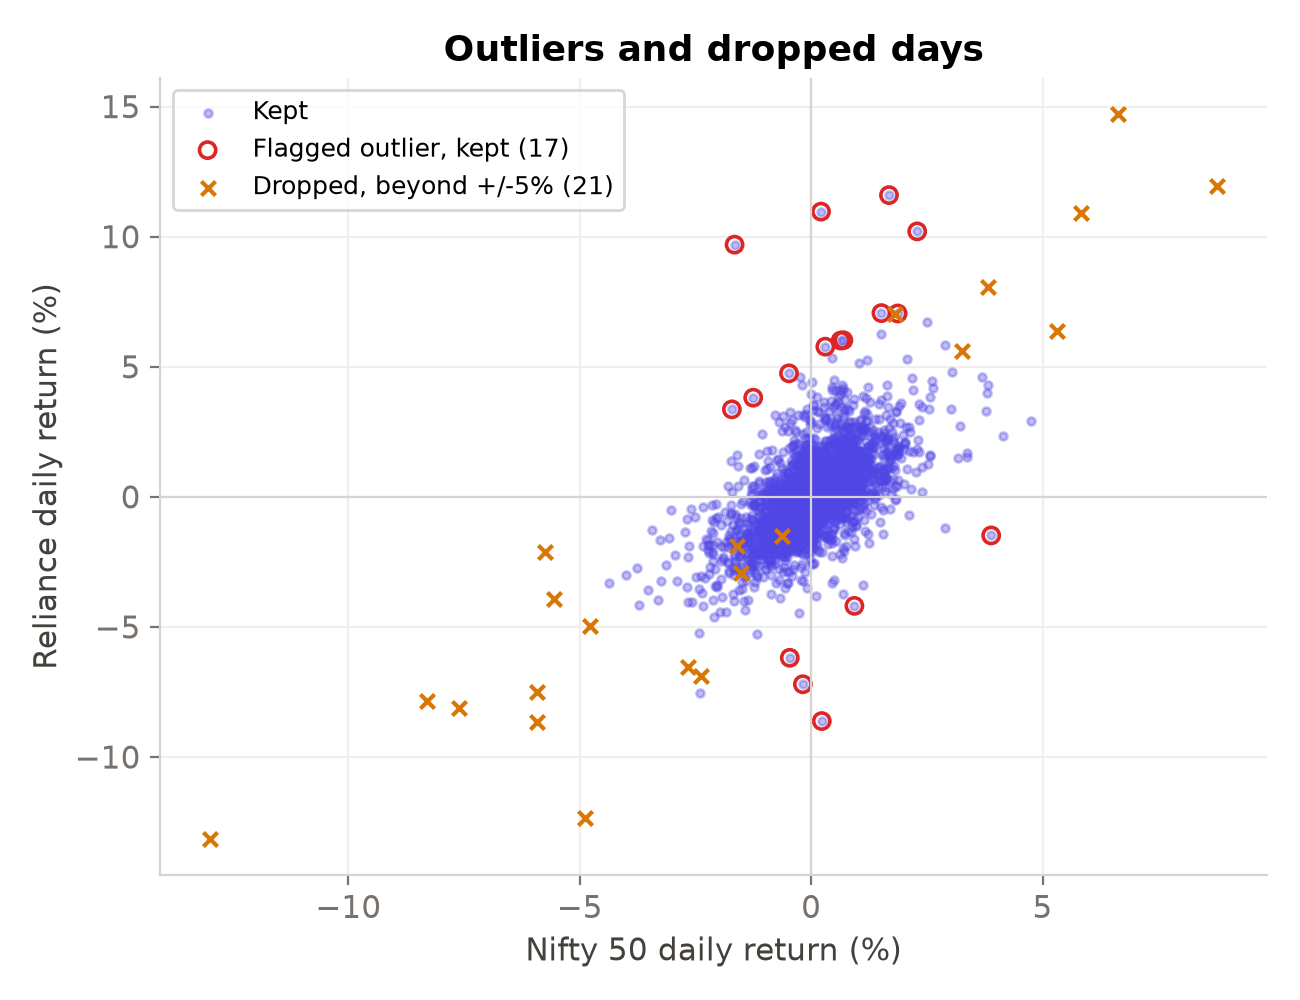

Predicted against actual daily returns on the most recent 25% of days.


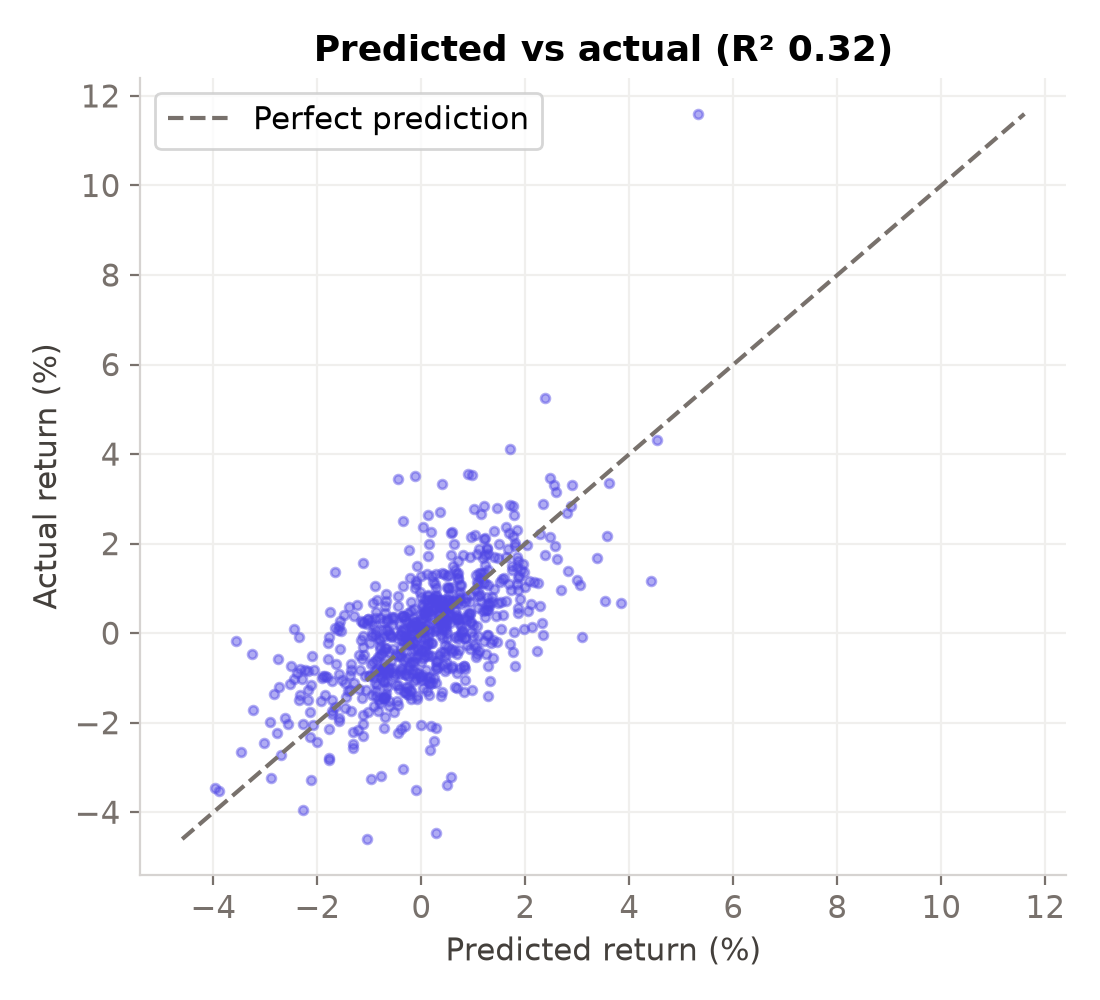

Residuals slope downward: the model over-predicts large moves in the recent period.


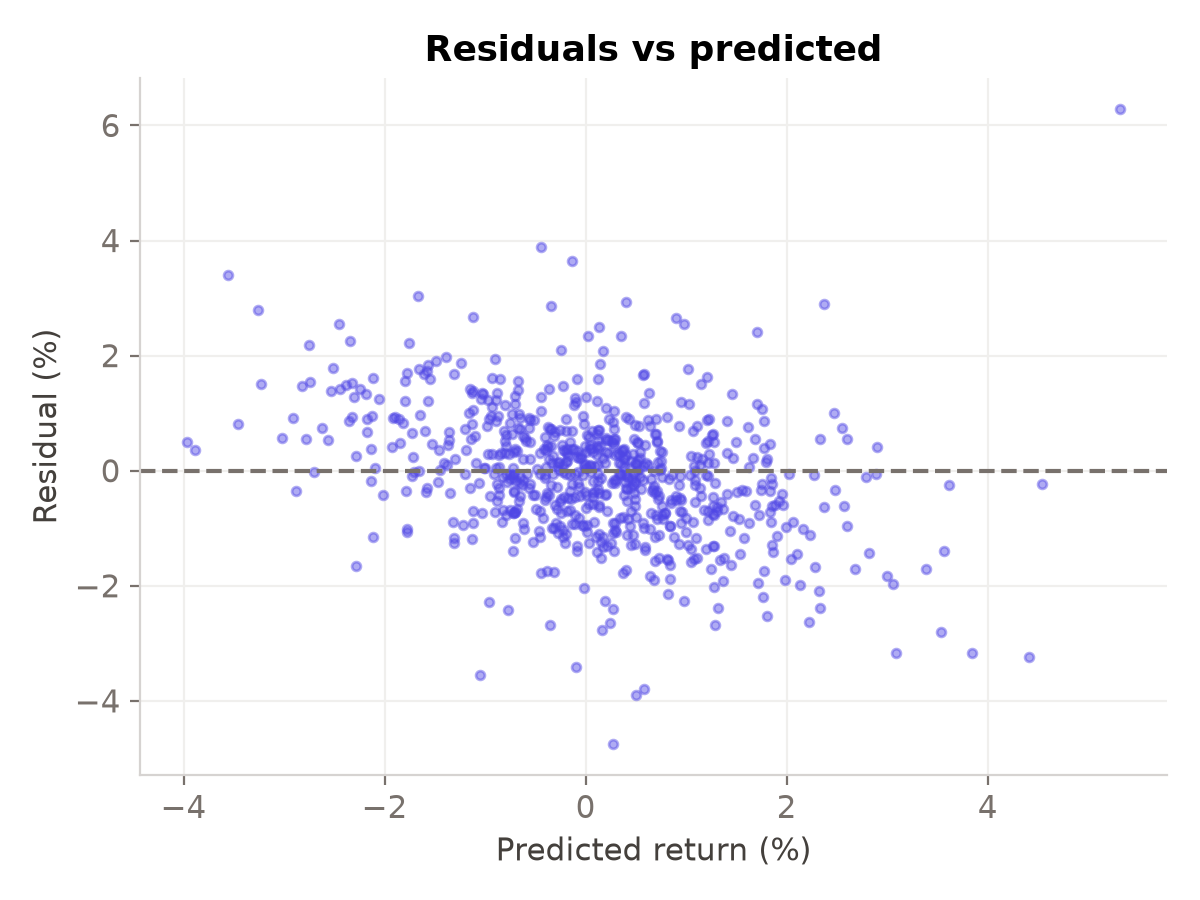

Learned coefficients: the sector index takes most of the weight because it contains Reliance itself.


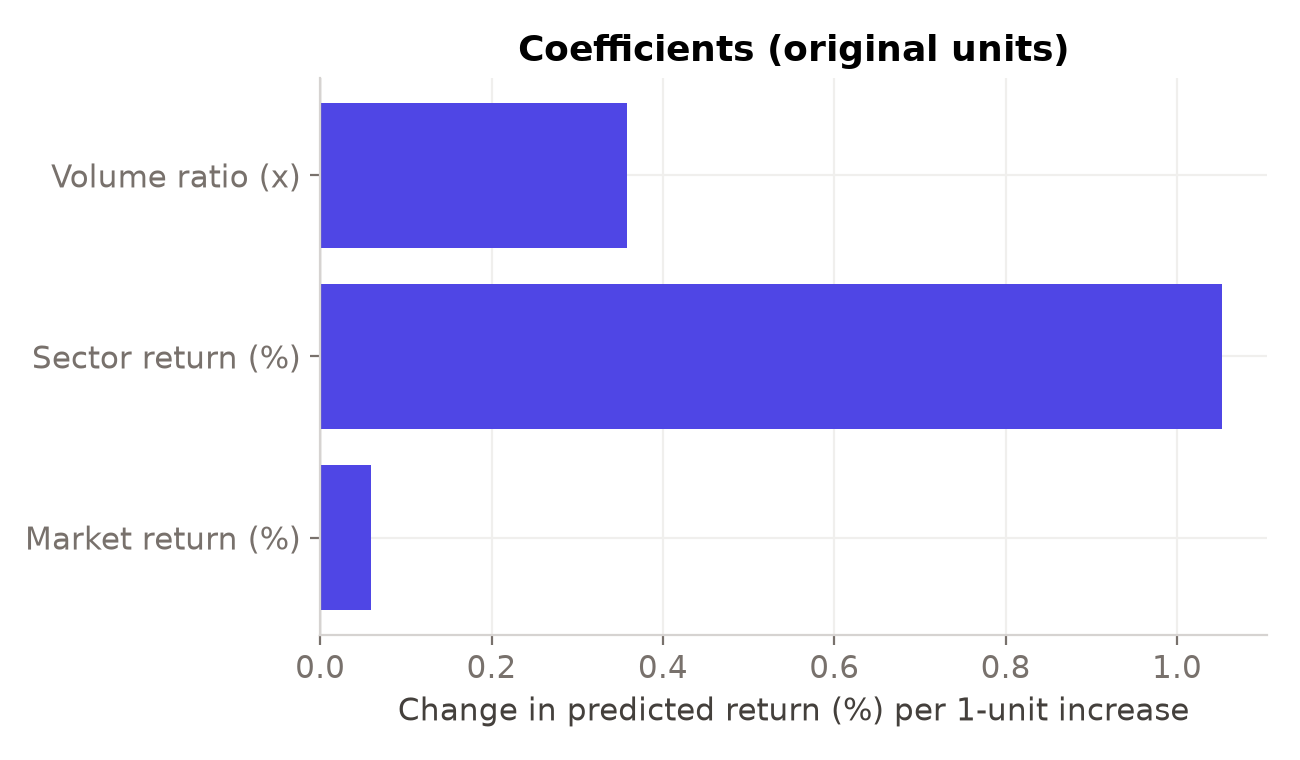

Residuals are centred near zero with a few large stock-specific misses in the tails.


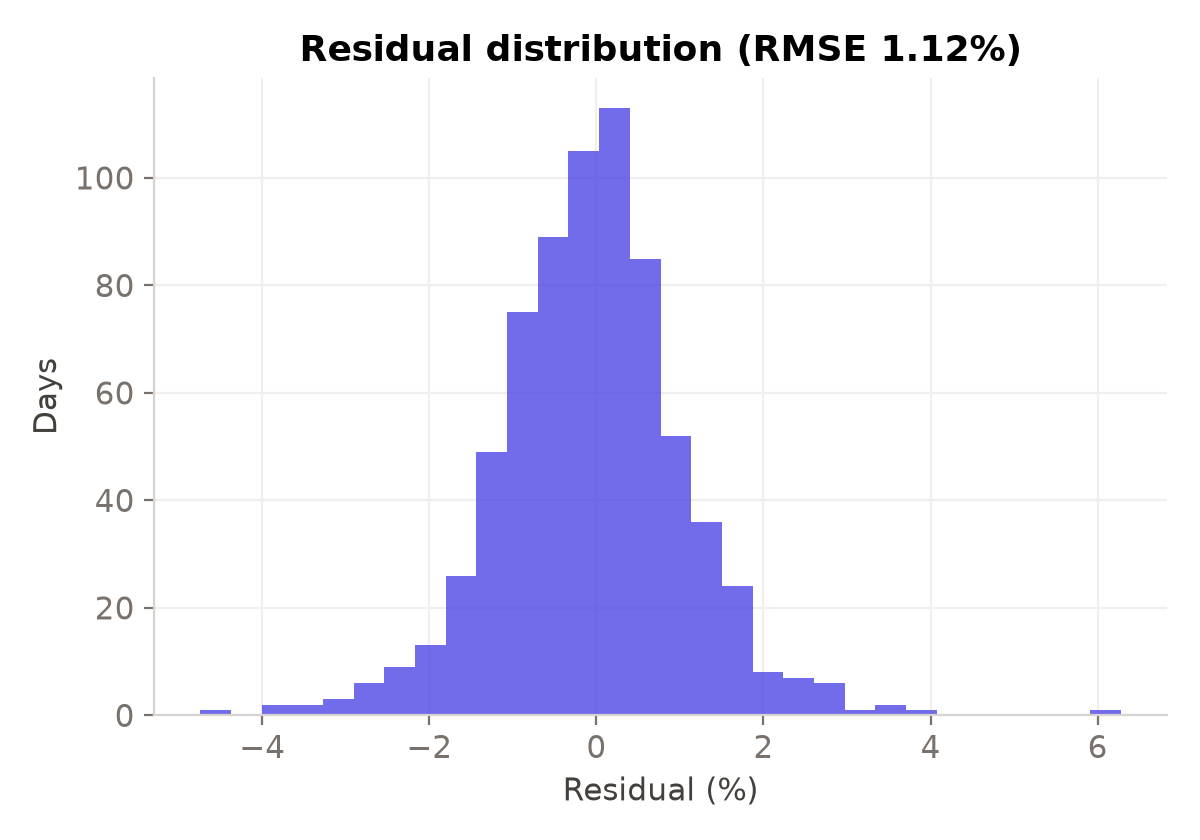

In [12]:
out = Path(tempfile.mkdtemp())
charts = make_charts(result, out)
for c in charts:
    print(c['caption'])
    display(Image(filename=str(out / c['file']), width=620))

## 6. Predict with the exported ONNX model

In [13]:
example = pd.DataFrame([PRESETS[1]['values']])[COLUMNS]
print('Sell-off preset ->', f"{onnx_predict(result.model_bytes, example)[0]:.2f}% predicted Reliance return")

Sell-off preset -> -2.27% predicted Reliance return


## Site artefacts

Run `uv run python train.py` to write `model.onnx`, `schema.json`, the charts and the .NET parity fixtures into the web app.